In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from google.colab import files

print('Please upload the `cars(1).csv` file.')
uploaded = files.upload()


Please upload the `cars(1).csv` file.


Saving cars.csv to cars.csv


In [3]:
df = pd.read_csv('cars.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (38531, 30)


,manufacturer_name,model_name,transmission,color,odometer_value,year_produced,engine_fuel,engine_has_gas,engine_type,engine_capacity,...,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,duration_listed
0,Subaru,Outback,automatic,silver,190000,2010,gasoline,False,gasoline,2.5,...,True,True,True,False,True,False,True,True,True,16
1,Subaru,Outback,automatic,blue,290000,2002,gasoline,False,gasoline,3.0,...,True,False,False,True,True,False,False,False,True,83
2,Subaru,Forester,automatic,red,402000,2001,gasoline,False,gasoline,2.5,...,True,False,False,False,False,False,False,True,True,151
3,Subaru,Impreza,mechanical,blue,10000,1999,gasoline,False,gasoline,3.0,...,False,False,False,False,False,False,False,False,False,86
4,Subaru,Legacy,automatic,black,280000,2001,gasoline,False,gasoline,2.5,...,True,False,True,True,False,False,False,False,True,7


In [ ]:
print("Dataset Information:")
print(df.info())

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38531 entries, 0 to 38530
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   manufacturer_name  38531 non-null  object 
 1   model_name         38531 non-null  object 
 2   transmission       38531 non-null  object 
 3   color              38531 non-null  object 
 4   odometer_value     38531 non-null  int64  
 5   year_produced      38531 non-null  int64  
 6   engine_fuel        38531 non-null  object 
 7   engine_has_gas     38531 non-null  bool   
 8   engine_type        38531 non-null  object 
 9   engine_capacity    38521 non-null  float64
 10  body_type          38531 non-null  object 
 11  has_warranty       38531 non-null  bool   
 12  state              38531 non-null  object 
 13  drivetrain         38531 non-null  object 
 14  price_usd          38531 non-null  float64
 15  is_exchangeable    38531 non-null  bool   
 16  l

,odometer_value,year_produced,engine_capacity,price_usd,number_of_photos,up_counter,duration_listed
count,38531.000000,38531.000000,38521.000000,38531.000000,38531.000000,38531.000000,38531.000000
mean,248864.638447,2002.943734,2.055161,6639.971021,9.649062,16.306091,80.577249
std,136072.376530,8.065731,0.671178,6428.152018,6.093217,43.286933,112.826569
min,0.000000,1942.000000,0.200000,1.000000,1.000000,1.000000,0.000000
25%,158000.000000,1998.000000,1.600000,2100.000000,5.000000,2.000000,23.000000
50%,250000.000000,2003.000000,2.000000,4800.000000,8.000000,5.000000,59.000000
75%,325000.000000,2009.000000,2.300000,8990.000000,12.000000,16.000000,91.000000
max,1000000.000000,2019.000000,8.000000,50000.000000,86.000000,1861.000000,2232.000000



Missing Values:
manufacturer_name     0
model_name            0
transmission          0
color                 0
odometer_value        0
year_produced         0
engine_fuel           0
engine_has_gas        0
engine_type           0
engine_capacity      10
body_type             0
has_warranty          0
state                 0
drivetrain            0
price_usd             0
is_exchangeable       0
location_region       0
number_of_photos      0
up_counter            0
feature_0             0
feature_1             0
feature_2             0
feature_3             0
feature_4             0
feature_5             0
feature_6             0
feature_7             0
feature_8             0
feature_9             0
duration_listed       0
dtype: int64

Duplicate Rows:
40


In [ ]:
df = df.drop_duplicates()

df['engine_capacity'] = df['engine_capacity'].fillna(
    df['engine_capacity'].median()
)

df = df[df['price_usd'] > 0]

print("Data cleaning completed!")
print("New shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

Data cleaning completed!
New shape: (38491, 30)
Missing values: 0


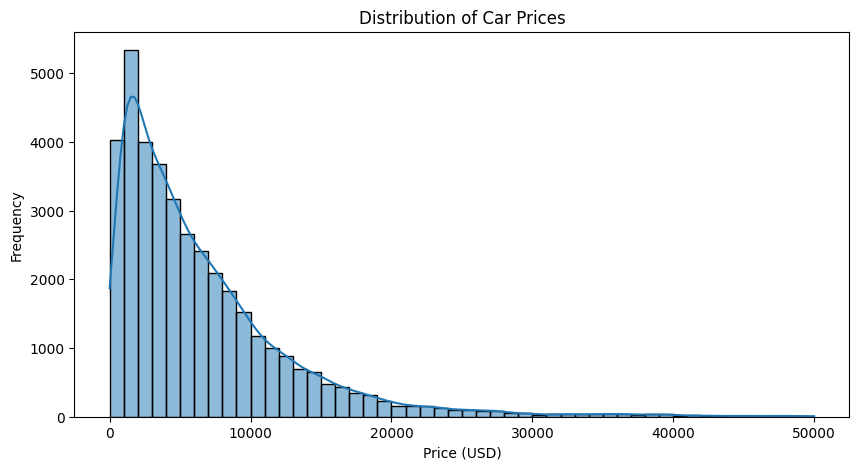

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(df['price_usd'], bins=50, kde=True)

plt.title("Distribution of Car Prices")
plt.xlabel("Price (USD)")
plt.ylabel("Frequency")

plt.show()

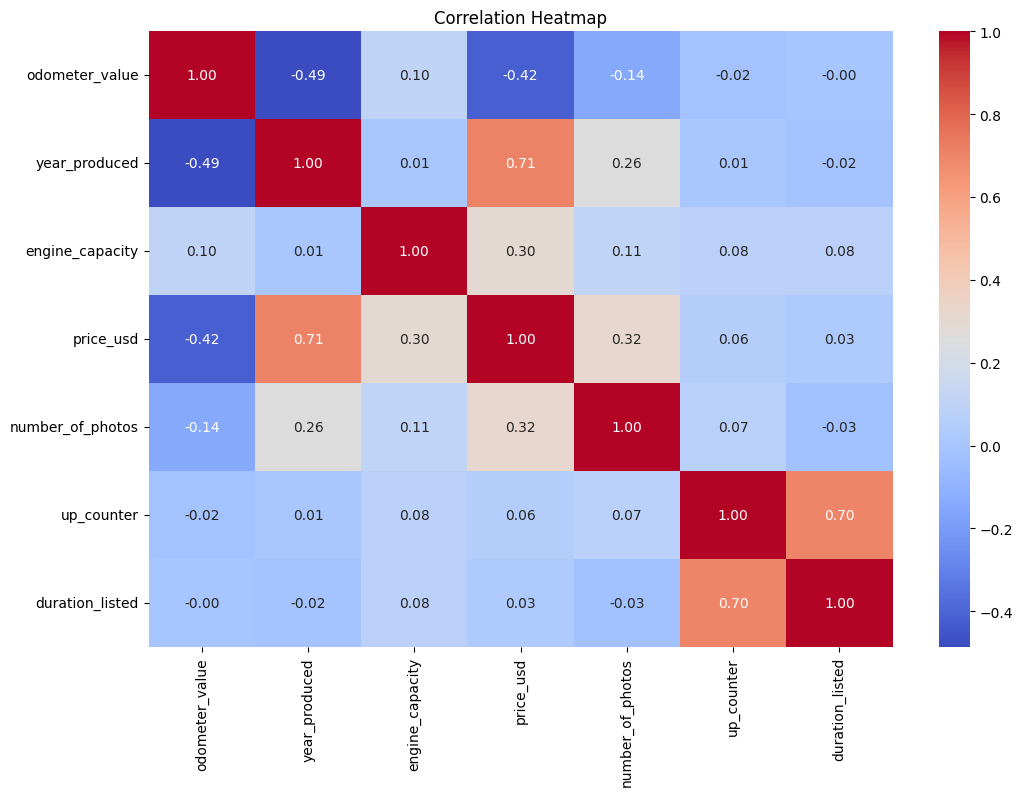

In [ ]:
plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

In [ ]:
X = df.drop(
    columns=['price_usd', 'duration_listed', 'up_counter']
)

y = df['price_usd']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (38491, 27)
Target: (38491,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 30792
Testing samples: 7699


In [ ]:
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'bool']
).columns.tolist()

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        min_frequency=2
    ))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline created!")

Numerical features: 4
Categorical features: 23
Preprocessing pipeline created!


In [ ]:
linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


In [ ]:
linear_r2 = r2_score(y_test, linear_predictions)

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

print("Linear Regression Results")
print("--------------------------")
print("R2 Score:", round(linear_r2, 4))
print("Accuracy:", round(linear_r2 * 100, 2), "%")
print("MAE:", round(linear_mae, 2))
print("RMSE:", round(linear_rmse, 2))

Linear Regression Results
--------------------------
R2 Score: 0.8291
Accuracy: 82.91 %
MAE: 1614.52
RMSE: 2629.03


In [ ]:
ridge_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

ridge_model = TransformedTargetRegressor(
    regressor=ridge_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

param_grid = {
    'regressor__model__alpha': [
        0.1, 1, 5, 10, 25, 50, 100
    ]
}

cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    ridge_model,
    param_grid,
    cv=cv,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-validation R2:", grid_search.best_score_)

Fitting 3 folds for each of 7 candidates, totalling 21 fits
Best Parameters: {'regressor__model__alpha': 1}
Best Cross-validation R2: 0.9046789024635723


In [ ]:
best_model = grid_search.best_estimator_

ridge_predictions = best_model.predict(X_test)

ridge_predictions = np.maximum(ridge_predictions, 0)

ridge_r2 = r2_score(y_test, ridge_predictions)

ridge_mae = mean_absolute_error(
    y_test,
    ridge_predictions
)

ridge_rmse = np.sqrt(
    mean_squared_error(y_test, ridge_predictions)
)

print("Optimized Ridge Regression Results")
print("----------------------------------")
print("R2 Score:", round(ridge_r2, 4))
print("Accuracy:", round(ridge_r2 * 100, 2), "%")
print("MAE:", round(ridge_mae, 2))
print("RMSE:", round(ridge_rmse, 2))

Optimized Ridge Regression Results
----------------------------------
R2 Score: 0.9069
Accuracy: 90.69 %
MAE: 1084.31
RMSE: 1940.84


In [ ]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Optimized Ridge Regression'
    ],
    'R2 Score': [
        linear_r2,
        ridge_r2
    ],
    'MAE': [
        linear_mae,
        ridge_mae
    ],
    'RMSE': [
        linear_rmse,
        ridge_rmse
    ]
})

display(results.sort_values(
    by='R2 Score',
    ascending=False
))

,Model,R2 Score,MAE,RMSE
1,Optimized Ridge Regression,0.906851,1084.305747,1940.841106
0,Linear Regression,0.829082,1614.522858,2629.032209


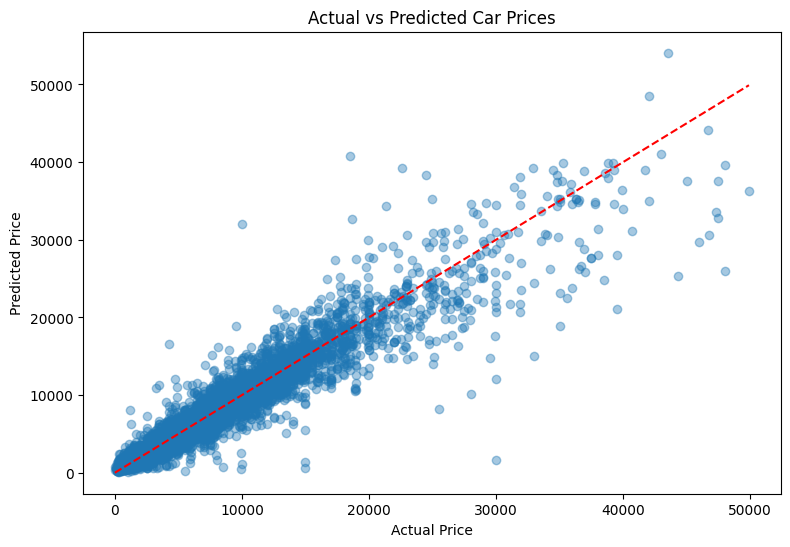

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    ridge_predictions,
    alpha=0.4
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()